# 04b: Barley seeds, classification (Table and Figure)

**Paper:** Section *Analysis of Real-World Barley Seed Data* (`sec:exp:barley`), paragraph *Results*:

| output | |
|---|---|
| Table `tab:exp:barley` | printed below as LaTeX rows |
| Figure `fig:exp:barley-pose` | `figures/4-barley/barley-pose.pdf` (values in `figures/4-barley/barley-pose.csv`) |
| numbers quoted in the text | the published UMAP pipeline (0.77 seed split, 0.08 spike split, 0.63 under random rotation), the ratio of principal variances (no seed above 0.8) |

**Protocol.** Every feature block is centred and scaled to unit mean squared norm (`barley.block`); the 11 traditional descriptors are standardized first and treated as one more block. The 28 seed types are classified with `SVC(C=10, gamma="scale")` (Gaussian kernel). Two splits, 20 repeats each, the same for every feature set (`barley.make_splits`):
* **seed split** (as in Amézquita et al. 2022): 25% of every type's seeds held out at random;
* **spike split**: one whole spike held out for every type with at least two spikes (26 of 28).

Inputs: the cached features from `04a-barley-preprocess.ipynb` (`data/barley/*.npz`) and the descriptor table and published UMAP from `00-data-barley.ipynb`. The CT scans are not needed.

Runtime: about 10 minutes on 14 CPU cores.

In [1]:
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from sklearn.preprocessing import StandardScaler

import barley as B

N_JOBS = max(1, (os.cpu_count() or 2) - 2)
OUT = B.ROOT / "figures" / "4-barley"
OUT.mkdir(parents=True, exist_ok=True)

POSES = ["paper", "automatic PCA", "scanner", "random rotation",
         "paper + 2°", "paper + 5°", "paper + 10°", "paper + 20°", "paper + 45°", "paper + 90°"]
FLIP_POSES = ["paper", "sign flips", "width/thickness swap", "swap + sign flips"]
BIN_VARIANTS = [(cx, b, p) for cx in ["voxel", "mesh"] for b in ["min-max", "global"]
                for p in ["paper", "random rotation"]]

d = B.load_table()
accession, panicle, traditional = d["accession"], d["panicle"], d["traditional"]
feats = dict(np.load(B.CACHE / "features.npz"))
flipped = np.load(B.CACHE / "flipflop.npz")["ect"]
binned = {k: np.load(B.CACHE / "binning.npz")["ect"][:, j] for j, k in enumerate(BIN_VARIANTS)}
splits = B.make_splits(accession, panicle)
SPLITS = list(splits)   # ["seed", "spike"]


def evaluate(x, gamma="scale"):
    return B.evaluate(x, accession, splits, gamma=gamma, n_jobs=N_JOBS)

## How well defined is the pose?

The paper's frame is the SVD of the voxel coordinates. Its axes are only as well defined as the gaps between the principal variances; the seeds are elongated, so the ratios between consecutive variances stay well below 1.

In [2]:
lam = feats["variances"]
r21, r32 = lam[:, 1] / lam[:, 0], lam[:, 2] / lam[:, 1]
print(f"lambda2/lambda1: median {np.median(r21):.2f}, max {r21.max():.2f}; "
      f"lambda3/lambda2: median {np.median(r32):.2f}, max {r32.max():.2f}")

lambda2/lambda1: median 0.33, max 0.72; lambda3/lambda2: median 0.65, max 0.80


## Accuracy of every feature set

In [3]:
trad = B.block(StandardScaler().fit_transform(traditional))
wect = {p: B.block(feats["wect"][:, k].astype(float)) for k, p in enumerate(POSES)}
flip = {p: B.block(flipped[:, k].astype(float)) for k, p in enumerate(FLIP_POSES)}
diwect = B.block(feats["diwect"])

FEATURES = {
    "traditional": trad,
    "DIWECT": diwect,
    **{f"WECT, {p}": wect[p] for p in POSES},
    **{f"WECT, {p} (flip-flop)": flip[p] for p in FLIP_POSES[1:]},
    "traditional + DIWECT": np.hstack([trad, diwect]),
    "traditional + WECT, paper": np.hstack([trad, wect["paper"]]),
    "traditional + WECT, swap + sign flips (flip-flop)": np.hstack([trad, flip["swap + sign flips"]]),
    "traditional + WECT, random rotation": np.hstack([trad, wect["random rotation"]]),
}
results = {name: evaluate(x) for name, x in FEATURES.items()}
print(f"{'features':>50}  {'dim':>5}   {'seed split':>13}   {'spike split':>13}")
for name, r in results.items():
    print(f"{name:>50}  {FEATURES[name].shape[1]:>5}   " + "   ".join(f"{r[s].mean():.3f} ± {r[s].std():.3f}" for s in SPLITS))

                                          features    dim      seed split     spike split
                                       traditional     11   0.527 ± 0.012   0.285 ± 0.024
                                            DIWECT     64   0.390 ± 0.012   0.238 ± 0.020
                                       WECT, paper   2528   0.446 ± 0.011   0.263 ± 0.025
                               WECT, automatic PCA   2528   0.347 ± 0.013   0.208 ± 0.018
                                     WECT, scanner   2528   0.321 ± 0.016   0.122 ± 0.009
                             WECT, random rotation   2528   0.105 ± 0.009   0.087 ± 0.008
                                  WECT, paper + 2°   2528   0.391 ± 0.015   0.242 ± 0.020
                                  WECT, paper + 5°   2528   0.312 ± 0.016   0.205 ± 0.014
                                 WECT, paper + 10°   2528   0.254 ± 0.008   0.171 ± 0.016
                                 WECT, paper + 20°   2528   0.168 ± 0.013   0.127 ± 0.011
          

## Table `tab:exp:barley`

"Flipped" is the hand-built frame with random axis sign flips and width/thickness swaps.

In [4]:
TABLE = [
    ("traditional descriptors", "traditional"),
    None,
    ("DIWECT", "DIWECT"),
    ("WECT, hand-built frame", "WECT, paper"),
    ("WECT, hand-built frame $+ 2^\\circ$", "WECT, paper + 2°"),
    ("WECT, flipped", "WECT, swap + sign flips (flip-flop)"),
    ("WECT, automatic PCA", "WECT, automatic PCA"),
    ("WECT, scanner", "WECT, scanner"),
    ("WECT, random rotation", "WECT, random rotation"),
    None,
    ("traditional $+$ DIWECT", "traditional + DIWECT"),
    ("traditional $+$ WECT, hand-built frame", "traditional + WECT, paper"),
    ("traditional $+$ WECT, flipped", "traditional + WECT, swap + sign flips (flip-flop)"),
    ("traditional $+$ WECT, random rotation", "traditional + WECT, random rotation"),
]
for row in TABLE:
    if row is None:
        print("\\addlinespace")
        continue
    label, key = row
    r = results[key]
    cells = " & ".join(f"${r[s].mean():.2f} \\pm {r[s].std():.2f}$" for s in SPLITS)
    print(f"{label} & {FEATURES[key].shape[1]:,} & {cells} \\\\")

traditional descriptors & 11 & $0.53 \pm 0.01$ & $0.28 \pm 0.02$ \\
\addlinespace
DIWECT & 64 & $0.39 \pm 0.01$ & $0.24 \pm 0.02$ \\
WECT, hand-built frame & 2,528 & $0.45 \pm 0.01$ & $0.26 \pm 0.02$ \\
WECT, hand-built frame $+ 2^\circ$ & 2,528 & $0.39 \pm 0.02$ & $0.24 \pm 0.02$ \\
WECT, flipped & 2,528 & $0.21 \pm 0.01$ & $0.16 \pm 0.01$ \\
WECT, automatic PCA & 2,528 & $0.35 \pm 0.01$ & $0.21 \pm 0.02$ \\
WECT, scanner & 2,528 & $0.32 \pm 0.02$ & $0.12 \pm 0.01$ \\
WECT, random rotation & 2,528 & $0.10 \pm 0.01$ & $0.09 \pm 0.01$ \\
\addlinespace
traditional $+$ DIWECT & 75 & $0.60 \pm 0.02$ & $0.31 \pm 0.03$ \\
traditional $+$ WECT, hand-built frame & 2,539 & $0.62 \pm 0.01$ & $0.33 \pm 0.04$ \\
traditional $+$ WECT, flipped & 2,539 & $0.44 \pm 0.01$ & $0.25 \pm 0.03$ \\
traditional $+$ WECT, random rotation & 2,539 & $0.39 \pm 0.01$ & $0.24 \pm 0.02$ \\


## Figure `fig:exp:barley-pose`

WECT accuracy (bars) as the pose degrades, against the DIWECT (blue line, band ± one sd over 20 splits). Left: seed split; right: spike split. The dotted line is chance (1/28).

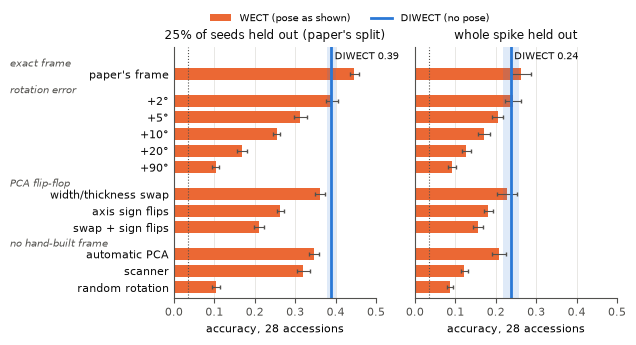

saved -> figures/4-barley/barley-pose.pdf


In [5]:
CONDITIONS = [  # (group, label, feature set)
    ("exact frame", "paper's frame", "WECT, paper"),
    ("rotation error", "+2°", "WECT, paper + 2°"),
    ("rotation error", "+5°", "WECT, paper + 5°"),
    ("rotation error", "+10°", "WECT, paper + 10°"),
    ("rotation error", "+20°", "WECT, paper + 20°"),
    ("rotation error", "+90°", "WECT, paper + 90°"),
    ("PCA flip-flop", "width/thickness swap", "WECT, width/thickness swap (flip-flop)"),
    ("PCA flip-flop", "axis sign flips", "WECT, sign flips (flip-flop)"),
    ("PCA flip-flop", "swap + sign flips", "WECT, swap + sign flips (flip-flop)"),
    ("no hand-built frame", "automatic PCA", "WECT, automatic PCA"),
    ("no hand-built frame", "scanner", "WECT, scanner"),
    ("no hand-built frame", "random rotation", "WECT, random rotation"),
]
rows = [("DIWECT", "", "DIWECT", results["DIWECT"])] + [("WECT", g, n, results[k]) for g, n, k in CONDITIONS]
pd.DataFrame([dict(features=f, group=g, pose=n, **{f"{s}_mean": r[s].mean() for s in SPLITS},
                   **{f"{s}_sd": r[s].std() for s in SPLITS}) for f, g, n, r in rows]
             ).to_csv(OUT / "barley-pose.csv", index=False)

BLUE, ORANGE, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 8, "axes.edgecolor": INK2, "xtick.color": INK2, "ytick.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
d_res = results["DIWECT"]
wrows = rows[1:]
ypos, labels, y, prev = [], [], 0, None
for f, g, n, r in wrows:            # a gap between groups
    if g != prev and prev is not None:
        y += 0.6
    ypos.append(y); labels.append(n); y += 1; prev = g
ypos = np.array(ypos)

fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.3), sharey=True)
for ax, (s, title) in zip(axes, [("seed", "25% of seeds held out (paper's split)"), ("spike", "whole spike held out")]):
    m = np.array([r[s].mean() for *_, r in wrows]); e = np.array([r[s].std() for *_, r in wrows])
    ax.barh(ypos, m, 0.72, xerr=e, color=ORANGE, error_kw=dict(ecolor=INK2, lw=0.8, capsize=1.5),
            label="WECT (pose as shown)")
    dm, ds = d_res[s].mean(), d_res[s].std()
    ax.axvspan(dm - ds, dm + ds, color=BLUE, alpha=0.15, lw=0)
    ax.axvline(dm, color=BLUE, lw=2, label="DIWECT (no pose)")
    ax.text(dm + 0.008, ypos[0] - 1.05, f"DIWECT {dm:.2f}", color=INK, fontsize=7.5, va="center")
    ax.axvline(1 / 28, color=INK2, lw=0.8, ls=":")
    ax.set_xlim(0, 0.5); ax.set_xlabel("accuracy, 28 accessions"); ax.set_title(title, fontsize=8.5, color=INK)
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(ypos); axes[0].set_yticklabels(labels); axes[0].invert_yaxis()
gstart = {}
for (f, g, n, r), yy in zip(wrows, ypos):
    gstart.setdefault(g, yy)
for g, yy in gstart.items():
    axes[0].annotate(g, xy=(0, yy - 0.62), xycoords=("axes fraction", "data"), xytext=(-118, 0),
                     textcoords="offset points", fontsize=7, color=INK2, style="italic", va="center",
                     annotation_clip=False)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h[::-1], l[::-1], loc="upper center", ncol=2, frameon=False, fontsize=7.5, bbox_to_anchor=(0.55, 1.04))
for ax in axes:
    ax.set_ylim(ypos[-1] + 0.6, ypos[0] - 1.6)
plt.tight_layout()
plt.savefig(OUT / "barley-pose.pdf", bbox_inches="tight")
plt.show()
print(f"saved -> {(OUT / 'barley-pose.pdf').relative_to(B.ROOT)}")

## The published UMAP pipeline (text, last paragraph of the section)

Amézquita et al. reduce the ECT to 12 dimensions with UMAP (50 neighbours, min_dist 0.1, Manhattan), fitted without labels on all seeds including the test seeds, then train an SVM ($\sigma = 0.1$, i.e. `gamma=0.1`) on the result.

* With the **published UMAP-12 coordinates**, the same splits as above.
* With UMAP-12 refitted on our reproduction of the published ECT (voxel complex, per-direction min–max binning; `data/barley/binning.npz`), in the paper's frame and with **every seed randomly rotated**.

In [6]:
def umap12(x):
    return umap.UMAP(n_neighbors=50, min_dist=0.1, metric="manhattan", n_components=12,
                     random_state=B.SEED).fit_transform(x)


published = pd.read_csv(B.UMAP_FILE, header=None).to_numpy(float)
umap_runs = {
    "published UMAP-12 of the published ECT": published,
    "UMAP-12 of the voxel min-max ECT, paper's frame": umap12(binned["voxel", "min-max", "paper"].astype(float)),
    "UMAP-12 of the voxel min-max ECT, random rotation": umap12(binned["voxel", "min-max", "random rotation"].astype(float)),
}
for name, u in umap_runs.items():
    r = evaluate(StandardScaler().fit_transform(u), gamma=0.1)
    print(f"{name:>52}: " + "   ".join(f"{s} split {r[s].mean():.3f} ± {r[s].std():.3f}" for s in SPLITS))

              published UMAP-12 of the published ECT: seed split 0.768 ± 0.013   spike split 0.078 ± 0.018


     UMAP-12 of the voxel min-max ECT, paper's frame: seed split 0.766 ± 0.014   spike split 0.089 ± 0.026


   UMAP-12 of the voxel min-max ECT, random rotation: seed split 0.633 ± 0.015   spike split 0.074 ± 0.024
